# Appendix C. Custom Code: Inventory, Unit Tests and Benchmarks

Everything in the `lmmtools` package was written for this companion; nothing else in the notebooks is custom. Each function is validated against numbers printed in the chapter (unit tests, C.4) and timed against third-party alternatives (C.5). The full source listings are reproduced at the end of the PDF appendix.

| Module / function | Purpose | Why custom | Used in |
|---|---|---|---|
| `lmmtools.reml.SparseREML` | REML/ML for iid random factors via the sparse mixed model equations; observed-information (SAS COVTEST) and average-information (ASReml) SEs; profile-likelihood CIs; ML/REML information criteria | statsmodels gives no variance-component SEs or profile CIs, and its dense algebra limits size | §2, §3, §4, App. B |
| `lmmtools.reml.boundary_lrt` | LRT with the Self & Liang (1987) boundary adjustment | convenience | §2 |
| `lmmtools.anova.FactorialANOVA` | SAS PROC GLM ANOVA: indicator coding, sweep g2-inverse, Type I/III SS with rank df, Type III EMS, synthesised F-tests (Satterthwaite), method-of-moments components, LS-means with estimability | statsmodels has no EMS or random-model tests, and its Type III differs from SAS's with empty cells | §1, §3 |
| `lmmtools.anova.sweep_ginv` | SAS-style g2 generalized inverse | not in NumPy/SciPy | §1, §3, §5 |
| `lmmtools.mme.solve_mme` | Henderson's MME for known variances: BLUE, BLUP, PEV, SEP, reliability | packaging of the chapter's matrix code | §4 |
| `lmmtools.design.incidence` | sparse incidence (Z) matrices | convenience | all |
| `lmmtools.data` | download + SHA-256 verification of the data | reproducibility | App. A |
| `lmmtools.report.check` | compare a result with the chapter's printed value | notebook assertions | all |

**Algorithms in brief.**

*SparseREML (C.1).* With $g_k = \sigma^2_k/\sigma^2_e$ and $Z^*_k = Z_k\sqrt{g_k}$, the coefficient matrix $C^* = \begin{bmatrix}X'X & X'Z^*\\ Z^{*\prime}X & I + Z^{*\prime}Z^*\end{bmatrix}$ is factorised by sparse LU (SuperLU with minimum-degree ordering). With $Q = y'y - \hat\theta'r$ (solutions $\hat\theta$, right-hand side $r$), $-2\log L_R = (n-p)\log(2\pi\sigma^2_e) + \log|C^*| + Q/\sigma^2_e$; $\sigma^2_e$ is profiled out ($\hat\sigma^2_e = Q/(n-p)$), and $g_k = t_k^2$ is optimised without bounds (zero variances allowed) by BFGS with central-difference gradients, followed by Newton polishing. ML subtracts $\log|X'H^{-1}X|$ and uses $n$. SEs come from the exact observed information $I_{ij} = -\tfrac12\operatorname{tr}(PV_iPV_j) + y'PV_iPV_jPy$ (dense, small n) or the average information $\tfrac12 y'PV_iPV_jPy$ (sparse solves only).

*FactorialANOVA (C.2).* Follows Goodnight (1978): with the sweep inverse $G$ of $X'X$ and the Hermite form $H = GX'X$, the Type III hypothesis for effect $F$ is the rows of $H$ for $F$ made orthogonal to the rows of every effect containing $F$. Its sum of squares is $(L\hat b)'(LGL')^{-}(L\hat b) = y'Qy$, and the EMS coefficient of $\sigma^2_k$ is $\operatorname{tr}(Z_k'QZ_k)/df$ (Hartley's synthesis). Denominators are synthesised by solving for mean-square coefficients that match the EMS without the tested component; their df follow Satterthwaite.

In [1]:
# Modules and imports for this appendix
import subprocess, sys, time, xml.etree.ElementTree as ET
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
import statsmodels.formula.api as smf
from lmmtools.data import load_maize
from lmmtools.design import incidence
from lmmtools.anova import FactorialANOVA
from lmmtools.reml import SparseREML
from lmmtools.mme import solve_mme
import warnings; warnings.filterwarnings("ignore")
pd.set_option("display.width", 100); pd.set_option("display.max_colwidth", 80)
ROOT = Path.cwd()

## C.4 Unit tests

The test suite (`tests/`) checks every custom function against values printed in the chapter: SAS PROC GLM and PROC MIXED output, lme4 and ASReml-R output, the lactation example, and the matrix appendix. It also checks the corrections (C6, C15, C17, C19, C21) and that statsmodels and pyreml agree with SAS (`slow` marker). Run it with `uv run pytest` (all) or `uv run pytest -m "not slow"`.

In [2]:
xml_path = ROOT / "tests" / "results.xml"
proc = subprocess.run([sys.executable, "-m", "pytest", "-q", f"--junitxml={xml_path}", "-p", "no:cacheprovider"],
                      cwd=ROOT, capture_output=True, text=True)
print(proc.stdout.strip().splitlines()[-1])
rows = []
for tc in ET.parse(xml_path).getroot().iter("testcase"):
    status = "failed" if tc.find("failure") is not None or tc.find("error") is not None else ("skipped" if tc.find("skipped") is not None else "passed")
    doc = tc.get("name")
    rows.append((tc.get("classname").split(".")[-1], doc, status, float(tc.get("time"))))
tests = pd.DataFrame(rows, columns=["module", "test", "status", "seconds"])
print(tests.to_string(index=False, float_format=lambda v: f"{v:.2f}"))
assert (tests.status == "passed").all(), "some tests did not pass"

33 passed, 3 warnings in 64.16s (0:01:04)
              module                                     test status  seconds
          test_anova                test_balanced_type1_type3 passed     0.23
          test_anova               test_balanced_random_tests passed     0.21
          test_anova             test_balanced_moments_and_h2 passed     0.20
          test_anova                    test_balanced_lsmeans passed     0.12
          test_anova              test_unbalanced_type1_type3 passed     0.26
          test_anova         test_unbalanced_ems_coefficients passed     0.20
          test_anova             test_unbalanced_random_tests passed     0.21
          test_anova    test_unbalanced_moments_correction_C6 passed     0.19
          test_anova    test_unbalanced_lsmeans_non_estimable passed     0.11
test_matrix_appendix                test_inner_outer_products passed     0.00
test_matrix_appendix test_transpose_of_product_reverses_order passed     0.00
test_matrix_appendix  

## C.5 Benchmarks

### Micro-benchmarks on the chapter's data

Median of five runs on the machine that built this document (2 CPU cores). statsmodels timings are given where it offers the same computation.

In [3]:
def timeit(f, k=5):
    ts = []
    for _ in range(k):
        t = time.perf_counter(); f(); ts.append(time.perf_counter() - t)
    return float(np.median(ts))

bal, miss = load_maize(True), load_maize(False)
terms = {"location": ("location",), "rep(location)": ("location", "rep"), "RIL": ("RIL",), "location*RIL": ("location", "RIL")}
Zb = [incidence(bal, f)[0] for f in ["location", ["location", "rep"], "RIL", ["location", "RIL"]]]
mb = SparseREML(bal.height, np.ones((len(bal), 1)), Zb)
fb = mb.fit(se=None)
y = np.array([110, 100, 110, 100, 100, 110, 110, 100, 100.]); X = np.eye(3)[[0, 0, 1, 1, 1, 2, 2, 2, 2]]; Z = np.eye(4)[[0, 3, 1, 3, 3, 2, 2, 3, 3]]
vc = {"a": "0 + C(location)", "b": "0 + C(location):C(rep)", "c": "0 + C(RIL)", "d": "0 + C(RIL):C(location)"}
bench = [
    ("FactorialANOVA: Type I + III (unbalanced, n=474)", lambda: (lambda a: (a.type1(), a.type3()))(FactorialANOVA(miss, "height", terms))),
    ("  statsmodels ols + anova_lm typ=1 (same model)", lambda: sm.stats.anova_lm(smf.ols("height ~ C(location) + C(location):C(rep) + C(RIL) + C(RIL):C(location)", miss).fit(), typ=1)),
    ("FactorialANOVA: EMS + random tests + moments (unbalanced)", lambda: (lambda a: (a.random_tests(), a.moments()))(FactorialANOVA(miss, "height", terms))),
    ("FactorialANOVA: LS-means with estimability (62 lines)", lambda: FactorialANOVA(miss, "height", terms).lsmeans("RIL")),
    ("SparseREML: REML fit, no SEs (balanced, n=496)", lambda: SparseREML(bal.height, np.ones((len(bal), 1)), Zb).fit(se=None)),
    ("SparseREML: observed-information SEs", lambda: mb.variance_se(fb.sigma2, fb.sigma2_e, "observed")),
    ("SparseREML: average-information SEs", lambda: mb.variance_se(fb.sigma2, fb.sigma2_e, "ai")),
    ("  statsmodels MixedLM REML fit (same model)", lambda: smf.mixedlm("height ~ 1", bal.assign(one=1), groups="one", vc_formula=vc).fit(reml=True, method=["bfgs"], gtol=1e-8)),
    ("SparseREML: one profile CI (RIL)", lambda: mb.profile_ci(fb, 2)),
    ("solve_mme: lactation example", lambda: solve_mme(X, [Z], y, 0.1, 1.0)),
]
micro = pd.DataFrame([(lab, timeit(f, 3 if "profile" in lab or "MixedLM" in lab else 5)) for lab, f in bench], columns=["task", "seconds (median)"])
print(micro.to_string(index=False, float_format=lambda v: f"{v:.3f}"))

                                                     task  seconds (median)
         FactorialANOVA: Type I + III (unbalanced, n=474)             0.219
            statsmodels ols + anova_lm typ=1 (same model)             0.045
FactorialANOVA: EMS + random tests + moments (unbalanced)             0.224
    FactorialANOVA: LS-means with estimability (62 lines)             0.113
           SparseREML: REML fit, no SEs (balanced, n=496)             0.828
                     SparseREML: observed-information SEs             0.064
                      SparseREML: average-information SEs             0.003
                statsmodels MixedLM REML fit (same model)             1.586
                         SparseREML: one profile CI (RIL)            16.070
                             solve_mme: lactation example             0.000


### Scaling: three REML engines on growing data sets

`benchmarks/bench_reml.py` fits the chapter's model ($\mu$ + location + rep(location) + RIL + RIL × location) with statsmodels, pyreml (CPU) and `SparseREML` to the two maize files and to simulated multi-environment trials of 62 to 2 000 lines in 4 to 25 locations. The variances are set to the chapter's REML estimates and 5% of plots are deleted at random. Each fit runs in its own process with a 15-minute limit; an engine that fails at one size is skipped at larger sizes. The last column is the largest relative difference of the five variance estimates from `SparseREML`.

REML fit time (status if not completed)
 engine                                          lmmtools statsmodels pyreml(CPU)
dataset                    n     random effects                                 
MaizeRILs (balanced)       496   322               1.4 s       2.3 s       2.8 s
MaizeRIL_miss (unbalanced) 474   322               2.2 s       2.3 s       2.8 s
sim. 62 lines x 4 locs     472   322               1.9 s       2.1 s       2.9 s
sim. 200 lines x 8 locs    3040  1824              4.5 s     189.5 s     189.3 s
sim. 500 lines x 10 locs   9500  5530             27.3 s     timeout     489.8 s
sim. 1000 lines x 20 locs  38000 21060           326.5 s     skipped     crashed
sim. 2000 lines x 25 locs  95000 52075           timeout     skipped     skipped

largest relative difference from lmmtools among the engines that finished
 dataset
MaizeRILs (balanced)          1.4e-06
MaizeRIL_miss (unbalanced)    1.2e-05
sim. 62 lines x 4 locs        1.2e-05
sim. 200 lines x 8 locs       7.

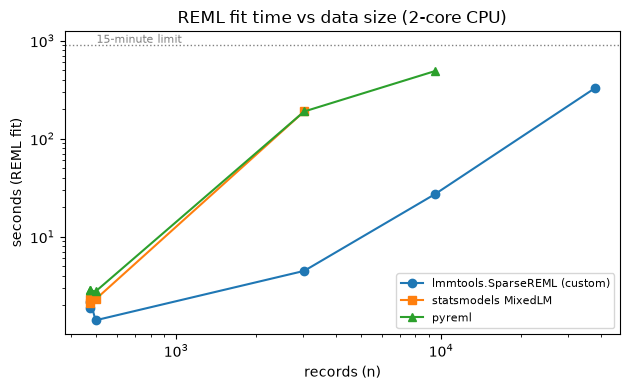

largest relative difference between engines where all converged: 1.6e-04


In [4]:
res = pd.read_csv(ROOT / "benchmarks" / "results.csv")
short = {"lmmtools.SparseREML (custom)": "lmmtools", "statsmodels MixedLM": "statsmodels", "pyreml": "pyreml(CPU)"}
res["dataset"] = (res.dataset.str.replace(r"simulated (\d+) lines x (\d+) locations", r"sim. \1 lines x \2 locs", regex=True)
                  .str.replace(r"\.csv \(", " (", regex=True))
cell = res.assign(engine=res.engine.map(short),
                  result=np.where(res.status == "ok", res.seconds.map(lambda s: f"{s:,.1f} s"), res.status.str.split(" ").str[0]))
table = cell.pivot_table(index=["dataset", "n", "random effects"], columns="engine", values="result", aggfunc="first", sort=False)
table = table[[c for c in short.values() if c in table.columns]]
print("REML fit time (status if not completed)\n", table.to_string())
dev = res[(res.status == "ok") & ~res.engine.str.startswith("lmmtools")].groupby("dataset", sort=False)["max rel. diff vs custom"].max()
print("\nlargest relative difference from lmmtools among the engines that finished\n", dev.map(lambda v: f"{v:.1e}").to_string())
ok = res[res.status == "ok"]
fig, ax = plt.subplots(figsize=(6.4, 4))
for (eng, g), mk in zip(ok.groupby("engine", sort=False), ["o", "s", "^"]):
    g = g.groupby("n", as_index=False).seconds.mean()
    ax.plot(g.n, g.seconds, marker=mk, label=eng)
ax.axhline(900, color="grey", ls=":", lw=1); ax.text(500, 950, "15-minute limit", fontsize=8, color="grey")
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlabel("records (n)"); ax.set_ylabel("seconds (REML fit)")
ax.set_title("REML fit time vs data size (2-core CPU)"); ax.legend(fontsize=8); plt.tight_layout(); plt.show()
agree = ok[ok.engine != "lmmtools.SparseREML (custom)"]["max rel. diff vs custom"].max()
print(f"largest relative difference between engines where all converged: {agree:.1e}")
assert agree < 1e-3

**Reading the benchmark.** On the chapter's data (≈500 records) the three engines take a few seconds and agree to about 10⁻⁵. At about 3 000 records statsmodels and pyreml take about 3 minutes, against seconds for the sparse custom code, which never forms the dense $n \times n$ matrix $V$ or dense $n \times q$ designs. At 9 500 records statsmodels exceeded the 15-minute limit and pyreml (CPU) took about 8 minutes. At 38 000 records pyreml ran out of memory (8 GB machine) and the custom code took about 5.5 minutes; at 95 000 records it too exceeded the limit, so very large evaluations call for dedicated software. pyreml's strengths are elsewhere (structured covariance and relationship matrices, multi-trait models, GPUs), and a CUDA device would change its timings. For models with relationship matrices or correlated structures, `SparseREML` does not apply, because it is limited to iid random factors.